In [1]:
# Dataset aur baseline model
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Load dataset
iris = load_iris(as_frame=True)
X = iris.data
y = iris.target

print("Dataset shape:", X.shape)
print("Classes:", iris.target_names)
print(X.head())

Dataset shape: (150, 4)
Classes: ['setosa' 'versicolor' 'virginica']
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2


In [2]:
# Baseline models
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, predictions))
print(classification_report(y_test, predictions, target_names=iris.target_names))

Accuracy: 0.9333333333333333
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [3]:
# prediction confidence
probabilities = model.predict_proba(X_test)

results = pd.DataFrame({
    "Actual": iris.target_names[y_test.to_numpy()],
    "Predicted": iris.target_names[predictions],
    "Confidence": probabilities.max(axis=1)
})

results["Review"] = results["Confidence"] < 0.70

print(results.head(15))
print("\nFlagged for review:", results["Review"].sum())

        Actual   Predicted  Confidence  Review
0       setosa      setosa    0.978818   False
1    virginica   virginica    0.626981    True
2   versicolor  versicolor    0.842475   False
3   versicolor  versicolor    0.894619   False
4       setosa      setosa    0.988493   False
5   versicolor  versicolor    0.675523    True
6       setosa      setosa    0.996230   False
7       setosa      setosa    0.941042   False
8    virginica   virginica    0.855697   False
9   versicolor  versicolor    0.737093   False
10   virginica   virginica    0.914911   False
11   virginica   virginica    0.947866   False
12   virginica   virginica    0.967801   False
13  versicolor  versicolor    0.789386   False
14      setosa      setosa    0.976515   False

Flagged for review: 5


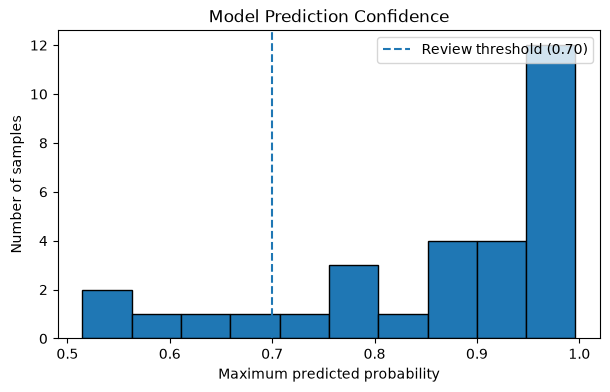

In [4]:
# Confidence Histogram + Calibration
# Confidence histogram
plt.figure(figsize=(7, 4))

plt.hist(results["Confidence"], bins=10, edgecolor="black")
plt.axvline(0.70, linestyle="--", label="Review threshold (0.70)")

plt.xlabel("Maximum predicted probability")
plt.ylabel("Number of samples")
plt.title("Model Prediction Confidence")
plt.legend()
plt.show()

Mean confidence: 0.862
Actual accuracy: 0.933


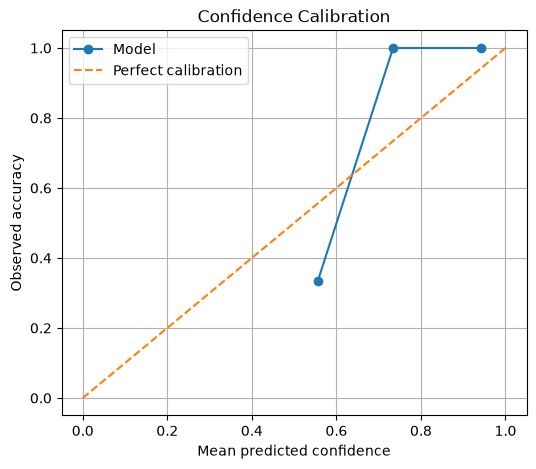

In [5]:
# Confidence comparison with actual accuracy
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

# Correct prediction = 1, incorrect = 0
correct = (predictions == y_test.to_numpy()).astype(int)
confidence = probabilities.max(axis=1)

print("Mean confidence:", round(confidence.mean(), 3))
print("Actual accuracy:", round(correct.mean(), 3))

# Calibration plot: confidence vs accuracy
prob_true, prob_pred = calibration_curve(
    correct,
    confidence,
    n_bins=5,
    strategy="uniform"
)

plt.figure(figsize=(6, 5))
plt.plot(prob_pred, prob_true, marker="o", label="Model")
plt.plot([0, 1], [0, 1], "--", label="Perfect calibration")

plt.xlabel("Mean predicted confidence")
plt.ylabel("Observed accuracy")
plt.title("Confidence Calibration")
plt.legend()
plt.grid(True)
plt.show()

In [6]:
# Selective Prediction
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Confidence and correctness for each test sample
confidence = probabilities.max(axis=1)
correct = (predictions == y_test.to_numpy())

thresholds = np.arange(0.50, 1.00, 0.05)
rows = []

for threshold in thresholds:
    accepted = confidence >= threshold

    coverage = accepted.mean()

    selective_accuracy = (
        correct[accepted].mean()
        if accepted.any()
        else np.nan
    )

    rows.append({
        "Threshold": round(threshold, 2),
        "Coverage": round(coverage, 3),
        "Selective Accuracy": round(selective_accuracy, 3),
        "Accepted Samples": int(accepted.sum())
    })

selective_results = pd.DataFrame(rows)
print(selective_results)

   Threshold  Coverage  Selective Accuracy  Accepted Samples
0       0.50     1.000               0.933                30
1       0.55     0.967               0.966                29
2       0.60     0.900               1.000                27
3       0.65     0.867               1.000                26
4       0.70     0.833               1.000                25
5       0.75     0.800               1.000                24
6       0.80     0.700               1.000                21
7       0.85     0.667               1.000                20
8       0.90     0.533               1.000                16
9       0.95     0.400               1.000                12


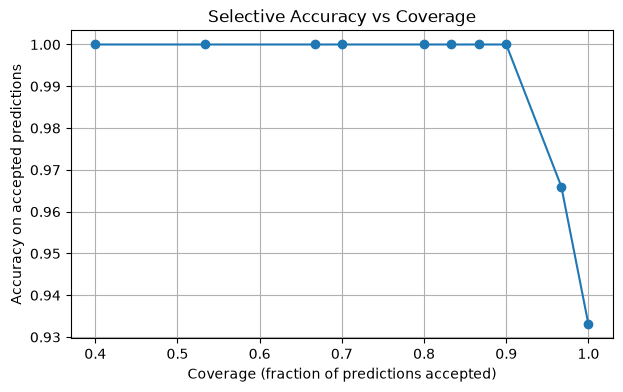

In [7]:
# Accuracy vs Coverage graph
plt.figure(figsize=(7, 4))

plt.plot(
    selective_results["Coverage"],
    selective_results["Selective Accuracy"],
    marker="o"
)

plt.xlabel("Coverage (fraction of predictions accepted)")
plt.ylabel("Accuracy on accepted predictions")
plt.title("Selective Accuracy vs Coverage")
plt.grid(True)

plt.show()

In [8]:
# experimental evaluation
import pandas as pd

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    ),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rows = []

for name, model in models.items():
    scores = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring=["accuracy", "f1_macro"]
    )

    rows.append({
        "Model": name,
        "Mean Accuracy": scores["test_accuracy"].mean(),
        "Accuracy Std": scores["test_accuracy"].std(),
        "Mean F1": scores["test_f1_macro"].mean()
    })

comparison = pd.DataFrame(rows).round(3)
print(comparison)

                 Model  Mean Accuracy  Accuracy Std  Mean F1
0  Logistic Regression          0.953         0.045    0.953
1        Decision Tree          0.953         0.034    0.953
2        Random Forest          0.947         0.027    0.946


In [9]:
# Research ka practical experiment
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import numpy as np
import pandas as pd

# Split into train, validation, and test sets
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, stratify=y, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42
)

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

model.fit(X_train, y_train)

# Choose threshold using validation data only
val_probs = model.predict_proba(X_val)
val_conf = val_probs.max(axis=1)

threshold = np.quantile(val_conf, 0.20)
print("Chosen threshold:", round(threshold, 3))

# Evaluate once on the held-out test set
test_probs = model.predict_proba(X_test)
test_conf = test_probs.max(axis=1)
test_pred = model.predict(X_test)

accepted = test_conf >= threshold
coverage = accepted.mean()

selective_accuracy = (
    accuracy_score(y_test.to_numpy()[accepted], test_pred[accepted])
    if accepted.any() else np.nan
)

print("Overall test accuracy:", round(
    accuracy_score(y_test, test_pred), 3
))
print("Coverage:", round(coverage, 3))
print("Accepted prediction accuracy:", round(selective_accuracy, 3))
print("Accepted samples:", accepted.sum(), "of", len(y_test))

Chosen threshold: 0.737
Overall test accuracy: 0.933
Coverage: 0.8
Accepted prediction accuracy: 1.0
Accepted samples: 24 of 30


In [10]:
# Final evaluation
import pandas as pd
import numpy as np

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Load dataset
iris = load_iris(as_frame=True)
X = iris.data
y = iris.target

# 60% training, 20% validation, 20% testing
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Train baseline model
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

model.fit(X_train, y_train)

# Predictions on untouched test set
y_pred = model.predict(X_test)
probs = model.predict_proba(X_test)
confidence = probs.max(axis=1)

# Baseline metrics
print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))
print()

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("Macro Precision:", round(
    precision_score(y_test, y_pred, average="macro", zero_division=0), 3
))
print("Macro Recall:", round(
    recall_score(y_test, y_pred, average="macro", zero_division=0), 3
))
print("Macro F1-score:", round(
    f1_score(y_test, y_pred, average="macro", zero_division=0), 3
))

Training samples: 90
Validation samples: 30
Testing samples: 30

Accuracy: 0.933
Macro Precision: 0.944
Macro Recall: 0.933
Macro F1-score: 0.933


In [11]:
# Uncertainty evaluation
# Select threshold using validation data only
val_probs = model.predict_proba(X_val)
val_confidence = val_probs.max(axis=1)

threshold = np.quantile(val_confidence, 0.20)

# Evaluate on test data
test_confidence = probs.max(axis=1)
correct = (y_pred == y_test.to_numpy())

accepted = test_confidence >= threshold

coverage = accepted.mean()
review_rate = 1 - coverage

selective_accuracy = (
    correct[accepted].mean()
    if accepted.any()
    else np.nan
)

print("Validation-selected threshold:", round(threshold, 3))
print("Baseline test accuracy:", round(correct.mean(), 3))
print("Coverage:", round(coverage, 3))
print("Review rate:", round(review_rate, 3))
print("Accepted prediction accuracy:", round(selective_accuracy, 3))
print("Accepted samples:", accepted.sum(), "out of", len(accepted))

Validation-selected threshold: 0.737
Baseline test accuracy: 0.933
Coverage: 0.8
Review rate: 0.2
Accepted prediction accuracy: 1.0
Accepted samples: 24 out of 30


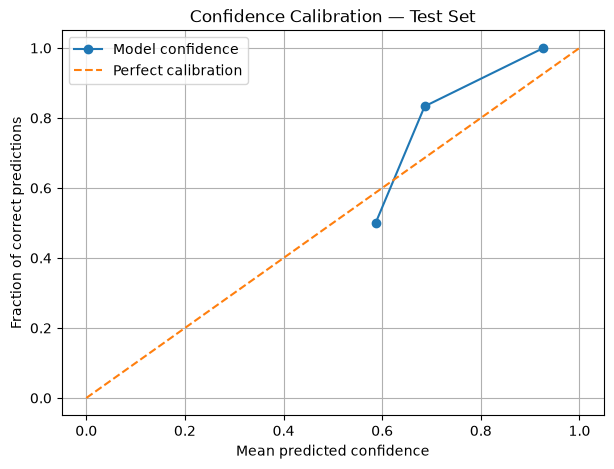

In [12]:
# Confidence calibration check
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

# Was each test prediction correct?
correct_binary = (y_pred == y_test.to_numpy()).astype(int)

# Compare confidence with actual correctness
fraction_correct, mean_confidence = calibration_curve(
    correct_binary,
    test_confidence,
    n_bins=5,
    strategy="uniform"
)

plt.figure(figsize=(7, 5))

plt.plot(
    mean_confidence,
    fraction_correct,
    marker="o",
    label="Model confidence"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Mean predicted confidence")
plt.ylabel("Fraction of correct predictions")
plt.title("Confidence Calibration — Test Set")
plt.legend()
plt.grid(True)
plt.show()

In [13]:
# calibration ka numerical score
from sklearn.metrics import brier_score_loss

brier_score = brier_score_loss(
    correct_binary,
    test_confidence
)

print("Brier Score:", round(brier_score, 4))

Brier Score: 0.0517


In [14]:
# Final results save
from pathlib import Path
import pandas as pd
import numpy as np

# Create results folder inside the project directory
results_dir = Path("results")
results_dir.mkdir(exist_ok=True)

# Save overall evaluation metrics
metrics = pd.DataFrame([{
    "test_samples": len(y_test),
    "baseline_accuracy": accuracy_score(y_test, y_pred),
    "macro_precision": precision_score(
        y_test, y_pred, average="macro", zero_division=0
    ),
    "macro_recall": recall_score(
        y_test, y_pred, average="macro", zero_division=0
    ),
    "macro_f1": f1_score(
        y_test, y_pred, average="macro", zero_division=0
    ),
    "confidence_threshold": threshold,
    "coverage": coverage,
    "review_rate": review_rate,
    "accepted_prediction_accuracy": selective_accuracy,
    "brier_score_binary_correctness": brier_score
}])

metrics.to_csv(results_dir / "evaluation_metrics.csv", index=False)

# Save each test prediction
predictions = X_test.reset_index(drop=True).copy()
predictions["actual_class"] = y_test.to_numpy()
predictions["predicted_class"] = y_pred
predictions["confidence"] = test_confidence
predictions["correct"] = correct
predictions["accepted"] = accepted

predictions.to_csv(
    results_dir / "test_predictions.csv",
    index=False
)

print("Saved:", results_dir / "evaluation_metrics.csv")
print("Saved:", results_dir / "test_predictions.csv")

Saved: results\evaluation_metrics.csv
Saved: results\test_predictions.csv


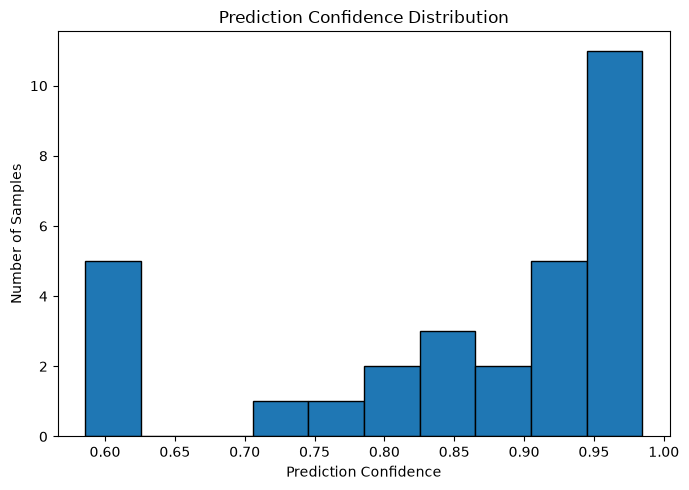

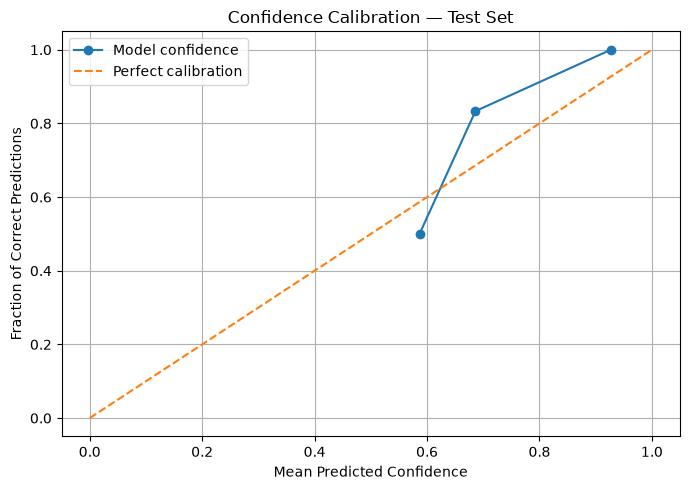

Both graphs saved successfully!


In [15]:
# Graphs save in files
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

# Create folder for figures
figures_dir = Path("results/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

# 1. Confidence distribution
plt.figure(figsize=(7, 5))
plt.hist(test_confidence, bins=10, edgecolor="black")
plt.xlabel("Prediction Confidence")
plt.ylabel("Number of Samples")
plt.title("Prediction Confidence Distribution")
plt.tight_layout()
plt.savefig(figures_dir / "confidence_distribution.png", dpi=300)
plt.show()

# 2. Calibration curve
plt.figure(figsize=(7, 5))
plt.plot(mean_confidence, fraction_correct, marker="o",
         label="Model confidence")
plt.plot([0, 1], [0, 1], "--", label="Perfect calibration")
plt.xlabel("Mean Predicted Confidence")
plt.ylabel("Fraction of Correct Predictions")
plt.title("Confidence Calibration — Test Set")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(figures_dir / "confidence_calibration.png", dpi=300)
plt.show()

print("Both graphs saved successfully!")